## 1. Imports and Config

In [1]:
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score,
    ConfusionMatrixDisplay
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')

artifacts = joblib.load('eda_artifacts.pkl')
df = artifacts['df']
num_features = artifacts['num_features']
iso_anomaly = artifacts['iso_anomaly']

print('Data loaded from EDA.')

Data loaded from EDA.


---
## 2. Data Preparation

In [2]:
df_model = df[num_features + ['Type', 'Target']].copy()
df_model = pd.get_dummies(df_model, columns=['Type'], drop_first=False)

feature_cols = [c for c in df_model.columns if c != 'Target']
X_all = df_model[feature_cols].values
y_all = df_model['Target'].values

X_train_calib, X_test, y_train_calib, y_test = train_test_split(
    X_all, y_all, test_size=0.15, random_state=17, stratify=y_all
)
X_train, X_calib, y_train, y_calib = train_test_split(
    X_train_calib, y_train_calib, test_size=0.176, random_state=17, stratify=y_train_calib
)
# 0.176 * 0.85 ≈ 0.15  ->  train≈70%, calib≈15%, test≈15%

scaler = StandardScaler()
X_train_sc       = scaler.fit_transform(X_train)
X_calib_sc       = scaler.transform(X_calib)
X_test_sc        = scaler.transform(X_test)
X_train_calib_sc = scaler.transform(X_train_calib)

print(f'Train: {X_train.shape[0]} samples')
print(f'Calib: {X_calib.shape[0]} samples')
print(f'Test:  {X_test.shape[0]} samples')
print(f'Train failures: {y_train.sum()} ({y_train.mean()*100:.1f}%)')
print(f'Calib failures: {y_calib.sum()} ({y_calib.mean()*100:.1f}%)')
print(f'Test  failures: {y_test.sum()}  ({y_test.mean()*100:.1f}%)')
print(f'\nFeatures: {len(feature_cols)}\n{feature_cols}')

Train: 7004 samples
Calib: 1496 samples
Test:  1500 samples
Train failures: 237 (3.4%)
Calib failures: 51 (3.4%)
Test  failures: 51  (3.4%)

Features: 8
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_H', 'Type_L', 'Type_M']


---
## 3. Hyperparameter Tuning - Optimal k

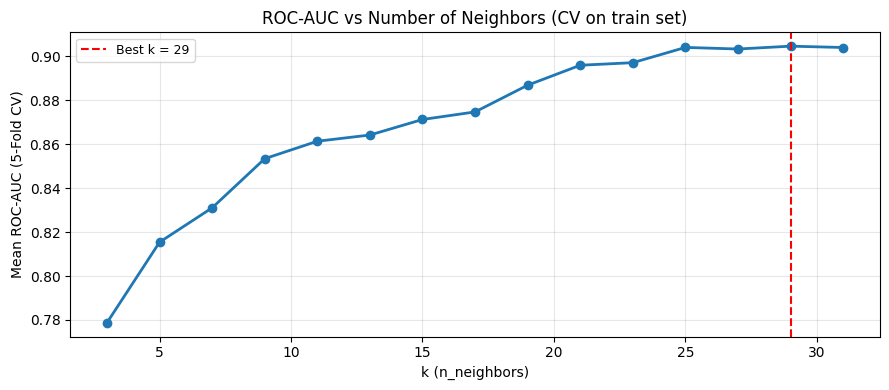

Best k: 29  (ROC-AUC = 0.9047


In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=17)

k_candidates = list(range(3, 32, 2))  # odd values only to avoid ties
mean_aucs = []

for k in k_candidates:
    knn_pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k, weights='distance', metric='minkowski', p=2))
    ])
    cv_res = cross_validate(
        knn_pipe, X_train, y_train, cv=cv,
        scoring='roc_auc', return_train_score=False
    )
    mean_aucs.append(cv_res['test_score'].mean())

best_k = k_candidates[np.argmax(mean_aucs)]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(k_candidates, mean_aucs, marker='o', lw=2)
ax.axvline(best_k, color='red', linestyle='--', lw=1.5, label=f'Best k = {best_k}')
ax.set_title('ROC-AUC vs Number of Neighbors (CV on train set)')
ax.set_xlabel('k (n_neighbors)')
ax.set_ylabel('Mean ROC-AUC (5-Fold CV)')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Best k: {best_k}  (ROC-AUC = {max(mean_aucs):.4f}')

---
## 4. Training and Basic Evaluation

In [4]:
knn = KNeighborsClassifier(
    n_neighbors=best_k,
    weights='distance',
    metric='minkowski',
    p=2
)
knn.fit(X_train_sc, y_train)

y_pred  = knn.predict(X_test_sc)
y_proba = knn.predict_proba(X_test_sc)[:, 1]

print('- Classification Report -')
print(classification_report(y_test, y_pred, target_names=['No Failure', 'Failure']))

roc_auc  = roc_auc_score(y_test, y_proba)
avg_prec = average_precision_score(y_test, y_proba)
print(f'ROC-AUC: {roc_auc:.4f}')
print(f'Average Precision: {avg_prec:.4f}')

- Classification Report -
              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1449
     Failure       1.00      0.12      0.21        51

    accuracy                           0.97      1500
   macro avg       0.98      0.56      0.60      1500
weighted avg       0.97      0.97      0.96      1500

ROC-AUC: 0.9534
Average Precision: 0.6516


---
## 5. Confusion Matrix

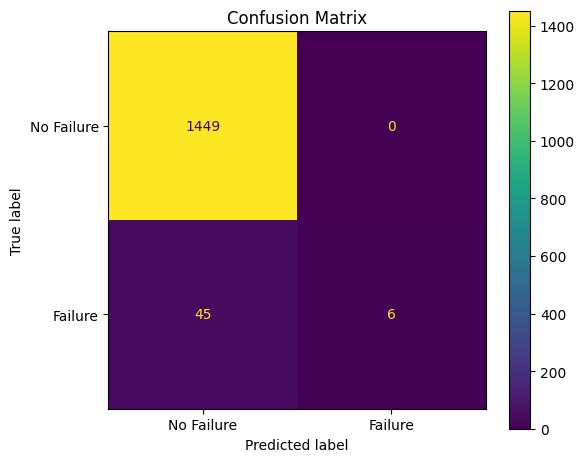


False Alarm Rate: 0.000
Miss Rate: 0.882


In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=['No Failure', 'Failure'])
disp.plot(ax=ax)
ax.set_title('Confusion Matrix')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'\nFalse Alarm Rate: {fp/(fp+tn):.3f}')
print(f'Miss Rate: {fn/(fn+tp):.3f}')

---
## 6. ROC Curve and Precision-Recall Curve

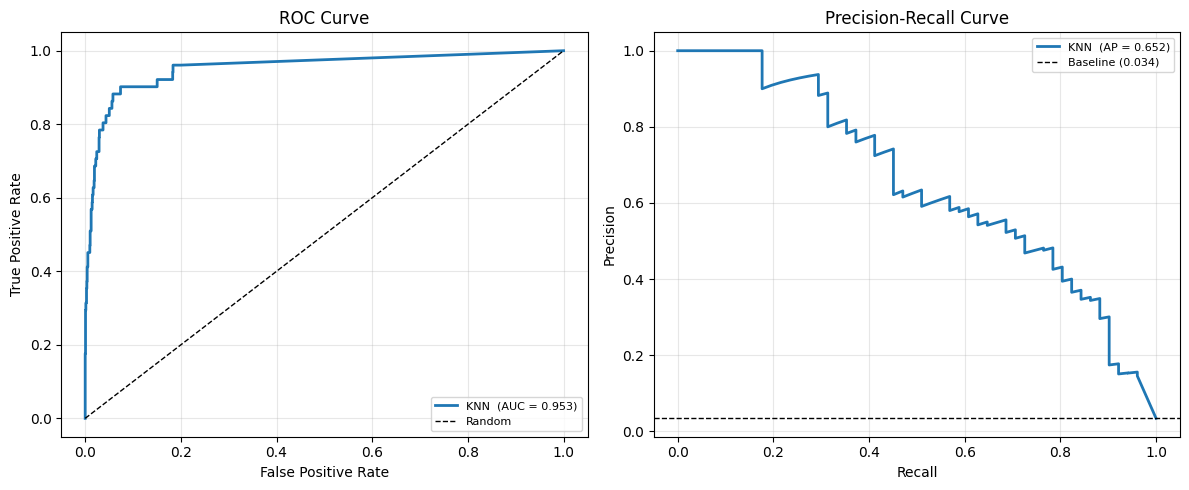

In [6]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
prec, rec, _ = precision_recall_curve(y_test, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC
ax = axes[0]
ax.plot(fpr, tpr, lw=2, label=f'KNN  (AUC = {roc_auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Precision-Recall
ax = axes[1]
ax.plot(rec, prec, lw=2, label=f'KNN  (AP = {avg_prec:.3f})')
baseline = y_test.mean()
ax.axhline(baseline, color='k', linestyle='--', lw=1, label=f'Baseline ({baseline:.3f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 7. Cross-validation (Stratified 5-Fold)

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=17)

knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(
        n_neighbors=best_k, weights='distance', metric='minkowski', p=2
    ))
])

cv_results = cross_validate(
    knn_pipeline, X_train_calib, y_train_calib, cv=cv,
    scoring=['roc_auc', 'average_precision', 'f1', 'recall', 'precision'],
    return_train_score=False
)

metrics = {
    'ROC-AUC': cv_results['test_roc_auc'],
    'Avg Precision': cv_results['test_average_precision'],
    'F1 (Failure)': cv_results['test_f1'],
    'Recall (Failure)': cv_results['test_recall'],
    'Precision (Failure)': cv_results['test_precision'],
}

print('- Cross-Validation Results (5-Fold on train+calib set) -')
print(f'{"Metric":<23} {"Mean":>8} {"Std":>8} {"Min":>8} {"Max":>8}')
print('-' * 60)
for name, vals in metrics.items():
    print(f'{name:<25} {vals.mean():>8.4f} {vals.std():>8.4f} {vals.min():>8.4f} {vals.max():>8.4f}')


- Cross-Validation Results (5-Fold on train+calib set) -
Metric                      Mean      Std      Min      Max
------------------------------------------------------------
ROC-AUC                     0.9203   0.0326   0.8792   0.9648
Avg Precision               0.5840   0.0618   0.4670   0.6412
F1 (Failure)                0.1207   0.0661   0.0667   0.2121
Recall (Failure)            0.0660   0.0387   0.0345   0.1207
Precision (Failure)         0.9750   0.0500   0.8750   1.0000


---
## 8. KNN Calibration

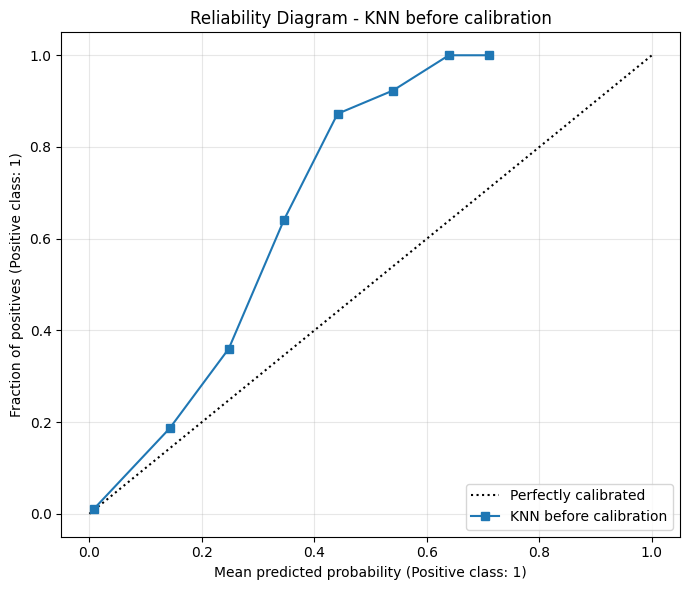

Points above the diagonal -> the model underestimates
Points below the diagonal -> the model overestimates


In [8]:
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.model_selection import cross_val_predict

y_proba_cv = cross_val_predict(
    Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(
            n_neighbors=best_k, weights='distance', metric='minkowski', p=2
        ))
    ]),
    X_train_calib, y_train_calib,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=17),
    method='predict_proba'
)[:, 1]

fig, ax = plt.subplots(figsize=(7, 6))
CalibrationDisplay.from_predictions(
    y_train_calib, y_proba_cv,
    n_bins=10, ax=ax,
    name='KNN before calibration'
)
ax.set_title('Reliability Diagram - KNN before calibration')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('Points above the diagonal -> the model underestimates')
print('Points below the diagonal -> the model overestimates')

---
## 9. Platt Scaling (Sigmoid) vs Isotonic Regression

In [9]:
base_knn = KNeighborsClassifier(
    n_neighbors=best_k, weights='distance', metric='minkowski', p=2
)
base_knn.fit(X_train_sc, y_train)

knn_sigmoid  = CalibratedClassifierCV(base_knn, method='sigmoid',  cv='prefit')
knn_isotonic = CalibratedClassifierCV(base_knn, method='isotonic', cv='prefit')

knn_sigmoid.fit(X_calib_sc,  y_calib)
knn_isotonic.fit(X_calib_sc, y_calib)

y_proba_sigmoid  = knn_sigmoid.predict_proba(X_test_sc)[:, 1]
y_proba_isotonic = knn_isotonic.predict_proba(X_test_sc)[:, 1]

y_proba = base_knn.predict_proba(X_test_sc)[:, 1]

print('Models calibrated. Predicted probabilities on the test set:')
print(f'Original KNN   - mean proba: {y_proba.mean():.4f}, std: {y_proba.std():.4f}')
print(f'KNN + Sigmoid  - mean proba: {y_proba_sigmoid.mean():.4f}, std: {y_proba_sigmoid.std():.4f}')
print(f'KNN + Isotonic - mean proba: {y_proba_isotonic.mean():.4f}, std: {y_proba_isotonic.std():.4f}')
print(f'Actual failure rate (test): {y_test.mean():.4f}')

Models calibrated. Predicted probabilities on the test set:
Original KNN   - mean proba: 0.0231, std: 0.0683
KNN + Sigmoid  - mean proba: 0.0324, std: 0.1110
KNN + Isotonic - mean proba: 0.0332, std: 0.1173
Actual failure rate (test): 0.0340


---
## 10. Reliability Diagram - comparison

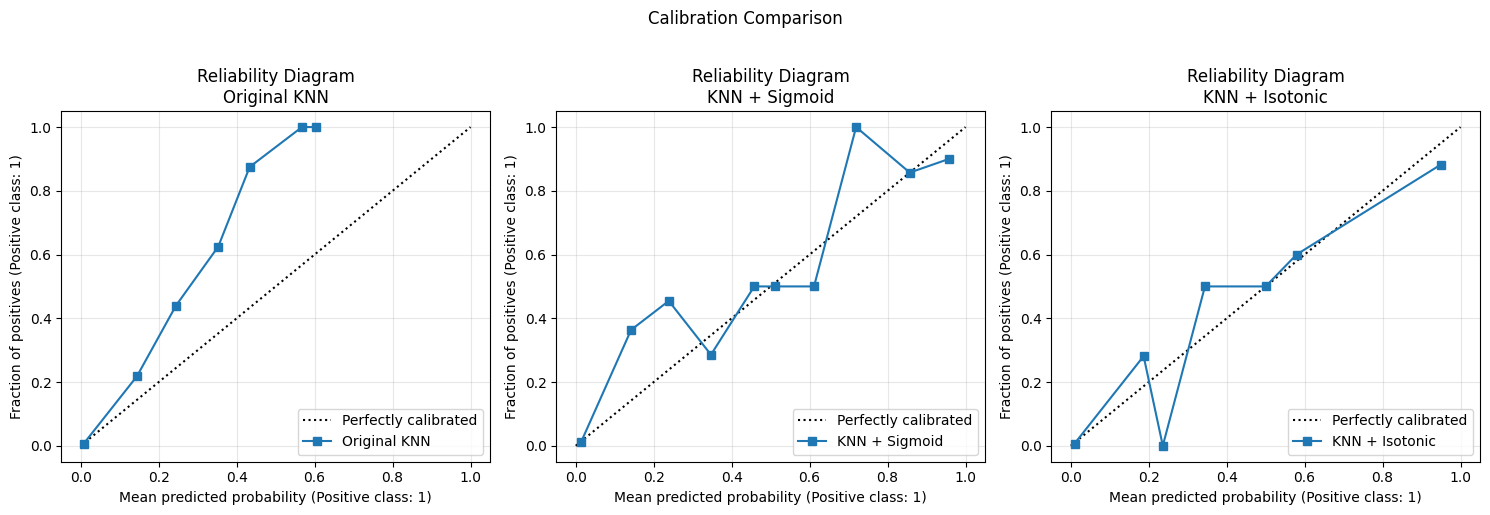

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

models_info = [
    (y_proba, 'Original KNN', axes[0]),
    (y_proba_sigmoid, 'KNN + Sigmoid', axes[1]),
    (y_proba_isotonic, 'KNN + Isotonic', axes[2]),
]

for proba, name, ax in models_info:
    CalibrationDisplay.from_predictions(
        y_test, proba, n_bins=10, ax=ax, name=name
    )
    ax.set_title(f'Reliability Diagram\n{name}')
    ax.grid(True, alpha=0.3)

plt.suptitle('Calibration Comparison', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

---
## 11. Brier Score

- Brier Score -
Baseline (naive): 0.032844
Original KNN: 0.021504  (skill: +0.3453)
KNN + Sigmoid: 0.019628  (skill: +0.4024)
KNN + Isotonic: 0.019308  (skill: +0.4121)


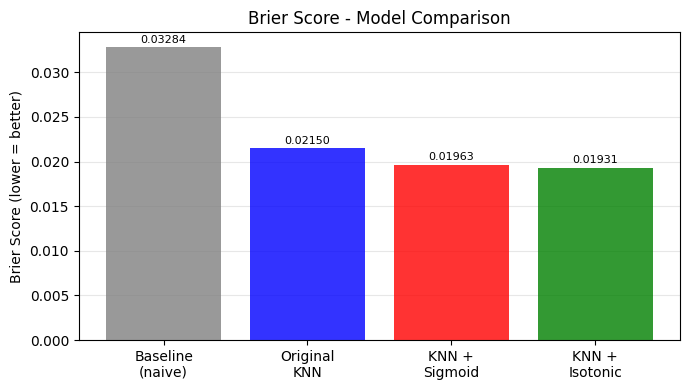

In [11]:
from sklearn.metrics import brier_score_loss

brier_orig     = brier_score_loss(y_test, y_proba)
brier_sigmoid  = brier_score_loss(y_test, y_proba_sigmoid)
brier_isotonic = brier_score_loss(y_test, y_proba_isotonic)

brier_baseline = brier_score_loss(
    y_test,
    np.full_like(y_test, y_test.mean(), dtype=float)
)

def brier_skill(brier, baseline):
    return 1 - brier / baseline

print('- Brier Score -')
print(f'Baseline (naive): {brier_baseline:.6f}')
print(f'Original KNN: {brier_orig:.6f}  (skill: {brier_skill(brier_orig, brier_baseline):+.4f})')
print(f'KNN + Sigmoid: {brier_sigmoid:.6f}  (skill: {brier_skill(brier_sigmoid, brier_baseline):+.4f})')
print(f'KNN + Isotonic: {brier_isotonic:.6f}  (skill: {brier_skill(brier_isotonic, brier_baseline):+.4f})')

fig, ax = plt.subplots(figsize=(7, 4))

names = [
    'Baseline\n(naive)',
    'Original\nKNN',
    'KNN +\nSigmoid',
    'KNN +\nIsotonic'
]

scores = [
    brier_baseline,
    brier_orig,
    brier_sigmoid,
    brier_isotonic
]

colors = ['gray', 'blue', 'red', 'green']

bars = ax.bar(names, scores, color=colors, alpha=0.8)

for bar, val in zip(bars, scores):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.0005,
        f'{val:.5f}',
        ha='center',
        fontsize=8
    )

ax.set_title('Brier Score - Model Comparison')
ax.set_ylabel('Brier Score (lower = better)')
ax.yaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

---
## 12. AUC / AP Comparison - Calibrated Models

Model                ROC-AUC   Avg Prec     Brier
--------------------------------------------------
Original KNN          0.9534     0.6516  0.021504
KNN + Sigmoid         0.9534     0.6516  0.019628
KNN + Isotonic        0.9521     0.5802  0.019308


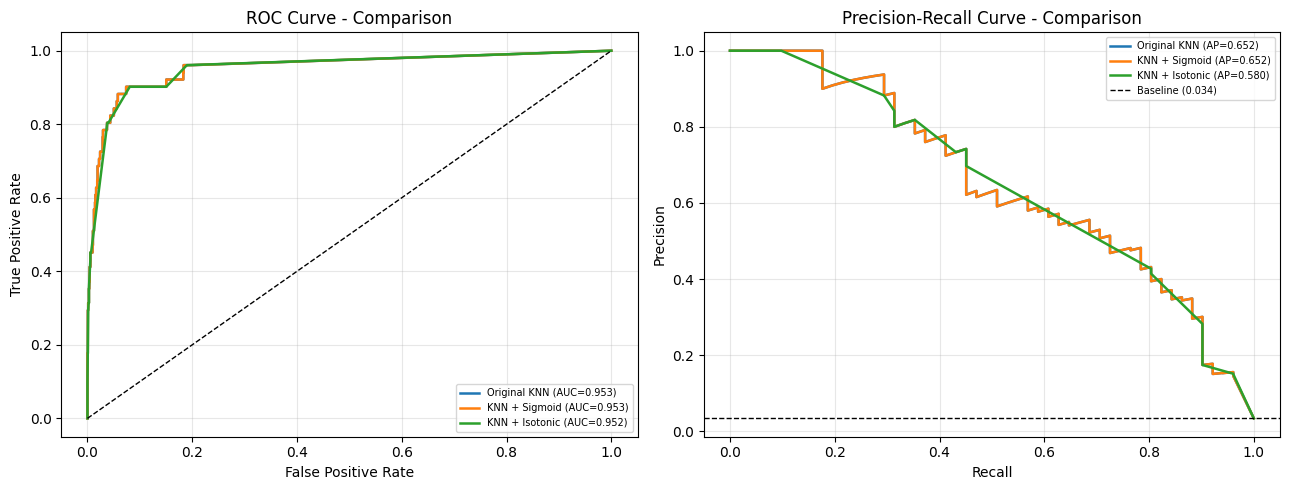

In [12]:
results = {
    'Original KNN': (
        y_proba,
        roc_auc_score(y_test, y_proba),
        average_precision_score(y_test, y_proba)
    ),
    'KNN + Sigmoid': (
        y_proba_sigmoid,
        roc_auc_score(y_test, y_proba_sigmoid),
        average_precision_score(y_test, y_proba_sigmoid)
    ),
    'KNN + Isotonic': (
        y_proba_isotonic,
        roc_auc_score(y_test, y_proba_isotonic),
        average_precision_score(y_test, y_proba_isotonic)
    ),
}

print(f'{"Model":<18} {"ROC-AUC":>9} {"Avg Prec":>10} {"Brier":>9}')
print('-' * 50)

briery = [brier_orig, brier_sigmoid, brier_isotonic]

for (name, (_, auc, ap)), brier in zip(results.items(), briery):
    print(f'{name:<18} {auc:>9.4f} {ap:>10.4f} {brier:>9.6f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, (proba, auc, ap) in results.items():
    fpr_i, tpr_i, _ = roc_curve(y_test, proba)
    axes[0].plot(
        fpr_i,
        tpr_i,
        lw=1.8,
        label=f'{name} (AUC={auc:.3f})'
    )

    prec_i, rec_i, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(
        rec_i,
        prec_i,
        lw=1.8,
        label=f'{name} (AP={ap:.3f})'
    )

axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_title('ROC Curve - Comparison')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(fontsize=7)
axes[0].grid(True, alpha=0.3)

axes[1].axhline(
    y_test.mean(),
    color='k',
    linestyle='--',
    lw=1,
    label=f'Baseline ({y_test.mean():.3f})'
)

axes[1].set_title('Precision-Recall Curve - Comparison')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(fontsize=7)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 13. Predicted Probability Distribution

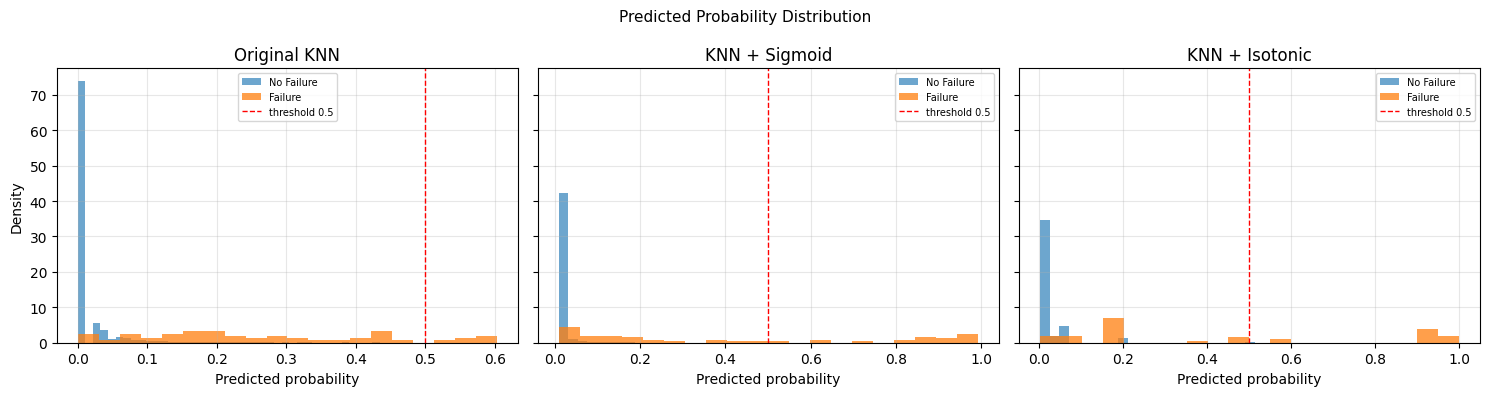

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

plot_data = [
    (y_proba, 'Original KNN',   axes[0]),
    (y_proba_sigmoid, 'KNN + Sigmoid',  axes[1]),
    (y_proba_isotonic, 'KNN + Isotonic', axes[2]),
]

for proba, name, ax in plot_data:
    ax.hist(proba[y_test==0], bins=40, alpha=0.65, density=True, label='No Failure')
    ax.hist(proba[y_test==1], bins=20, alpha=0.75, density=True, label='Failure')
    ax.axvline(0.5, color='red', linestyle='--', lw=1, label='threshold 0.5')
    ax.set_title(name)
    ax.set_xlabel('Predicted probability')
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel('Density')
plt.suptitle('Predicted Probability Distribution', fontsize=11)
plt.tight_layout()
plt.show()

---
## 14. Decision Threshold Optimization

Selected model for threshold analysis: KNN + Isotonic


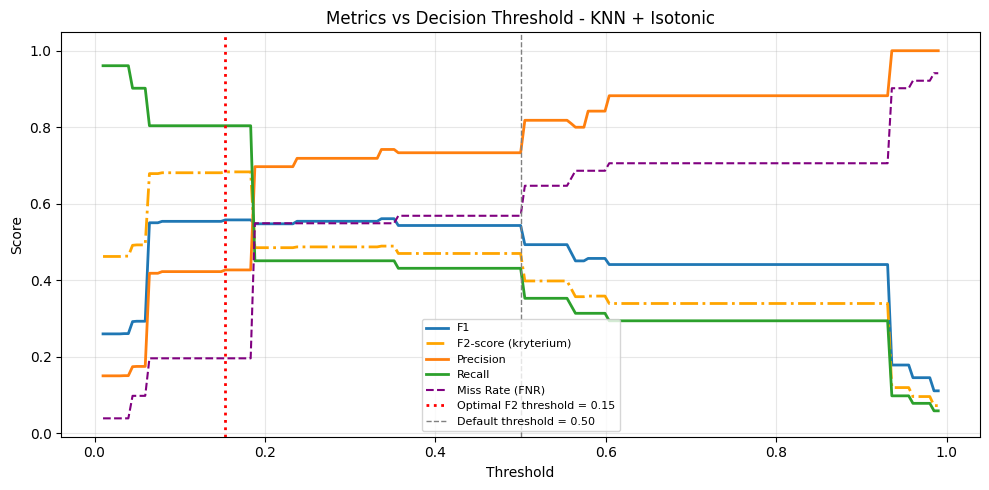


- Default threshold (0.50) -
              precision    recall  f1-score   support

  No Failure       0.98      0.99      0.99      1449
     Failure       0.73      0.43      0.54        51

    accuracy                           0.98      1500
   macro avg       0.86      0.71      0.77      1500
weighted avg       0.97      0.98      0.97      1500


- Optimal F2 threshold (0.15) -
              precision    recall  f1-score   support

  No Failure       0.99      0.96      0.98      1449
     Failure       0.43      0.80      0.56        51

    accuracy                           0.96      1500
   macro avg       0.71      0.88      0.77      1500
weighted avg       0.97      0.96      0.96      1500


- Metric Changes Comparison -
Metric                    Threshold 0.50  Opt. Threshold     Change
------------------------------------------------------------
F1-score                        0.5432       0.5578    +0.0146
F{BETA}-score                   0.4701       0.6833    +0.21

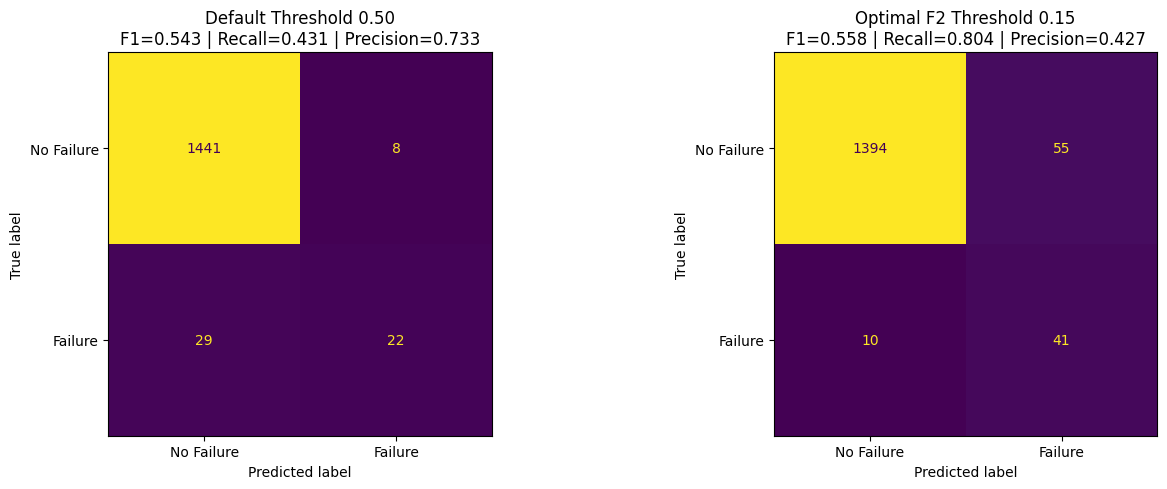

In [14]:
from sklearn.metrics import f1_score, fbeta_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

BETA = 2  # recall is 2 times more important than precision for failure detection

all_variants = [
    ('Original KNN', y_proba, brier_orig),
    ('KNN + Sigmoid', y_proba_sigmoid, brier_sigmoid),
    ('KNN + Isotonic', y_proba_isotonic, brier_isotonic),
]
best_name, best_proba, _ = min(all_variants, key=lambda x: x[2])
print(f'Selected model for threshold analysis: {best_name}')

thresholds = np.linspace(0.01, 0.99, 199)
f1s, fbs, precs, recs, fnrs = [], [], [], [], []

for t in thresholds:
    y_t = (best_proba >= t).astype(int)
    f1s.append(f1_score(y_test, y_t, zero_division=0))
    fbs.append(fbeta_score(y_test, y_t, beta=BETA, zero_division=0))
    precs.append(precision_score(y_test, y_t, zero_division=0))
    recs.append(recall_score(y_test, y_t, zero_division=0))
    cm_t = confusion_matrix(y_test, y_t)
    tn_t, fp_t, fn_t, tp_t = cm_t.ravel() if cm_t.size == 4 else (0, 0, 0, 0)
    fnrs.append(fn_t / (fn_t + tp_t + 1e-9))

best_t_idx = np.argmax(fbs)
best_t = thresholds[best_t_idx]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(thresholds, f1s,   lw=2, label='F1')
ax.plot(thresholds, fbs,   lw=2, linestyle='-.', color='orange', label=f'F{BETA}-score (kryterium)')
ax.plot(thresholds, precs, lw=2, label='Precision')
ax.plot(thresholds, recs,  lw=2, label='Recall')
ax.plot(thresholds, fnrs,  lw=1.5, linestyle='--', color='purple', label='Miss Rate (FNR)')
ax.axvline(best_t, color='red', linestyle=':', lw=2, label=f'Optimal F{BETA} threshold = {best_t:.2f}')
ax.axvline(0.5, color='gray', linestyle='--', lw=1, label='Default threshold = 0.50')
ax.set_title(f'Metrics vs Decision Threshold - {best_name}')
ax.set_xlabel('Threshold')
ax.set_ylabel('Score')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'\n- Default threshold (0.50) -')
y_default = (best_proba >= 0.50).astype(int)
print(classification_report(y_test, y_default, target_names=['No Failure', 'Failure']))

print(f'\n- Optimal F{BETA} threshold ({best_t:.2f}) -')
y_optimal = (best_proba >= best_t).astype(int)
print(classification_report(y_test, y_optimal, target_names=['No Failure', 'Failure']))

print("\n- Metric Changes Comparison -")

f1_def   = f1_score(y_test, y_default, zero_division=0)
prec_def = precision_score(y_test, y_default, zero_division=0)
rec_def  = recall_score(y_test, y_default, zero_division=0)
fb_def   = fbeta_score(y_test, y_default, beta=BETA, zero_division=0)

f1_opt   = f1_score(y_test, y_optimal, zero_division=0)
prec_opt = precision_score(y_test, y_optimal, zero_division=0)
rec_opt  = recall_score(y_test, y_optimal, zero_division=0)
fb_opt   = fbeta_score(y_test, y_optimal, beta=BETA, zero_division=0)

cm_def = confusion_matrix(y_test, y_default)
tn_def, fp_def, fn_def, tp_def = cm_def.ravel()
fnr_def = fn_def / (fn_def + tp_def)

cm_opt = confusion_matrix(y_test, y_optimal)
tn_opt, fp_opt, fn_opt, tp_opt = cm_opt.ravel()
fnr_opt = fn_opt / (fn_opt + tp_opt)

print(f"{'Metric':<25} {'Threshold 0.50':>14} {'Opt. Threshold':>15} {'Change':>10}")
print("-" * 60)
print(f"{'F1-score':<25} {f1_def:>12.4f} {f1_opt:>12.4f} {f1_opt - f1_def:>+10.4f}")
print(f"{'F{BETA}-score':<25} {fb_def:>12.4f} {fb_opt:>12.4f} {fb_opt - fb_def:>+10.4f}")
print(f"{'Precision':<25} {prec_def:>12.4f} {prec_opt:>12.4f} {prec_opt - prec_def:>+10.4f}")
print(f"{'Recall':<25} {rec_def:>12.4f} {rec_opt:>12.4f} {rec_opt - rec_def:>+10.4f}")
print(f"{'Miss Rate (FNR)':<25} {fnr_def:>12.4f} {fnr_opt:>12.4f} {fnr_opt - fnr_def:>+10.4f}")
print(f"{'True Positives':<25} {tp_def:>12} {tp_opt:>12} {tp_opt - tp_def:>+10}")
print(f"{'False Positives':<25} {fp_def:>12} {fp_opt:>12} {fp_opt - fp_def:>+10}")
print(f"{'False Negatives':<25} {fn_def:>12} {fn_opt:>12} {fn_opt - fn_def:>+10}")
print(f"{'True Negatives':<25} {tn_def:>12} {tn_opt:>12} {tn_opt - tn_def:>+10}")

print("\nInterpretation:")
print(
    f"The optimal F{BETA} threshold ({best_t:.2f}) improved failure detection compared to the default (0.50): "
    f"recall rose by {rec_opt - rec_def:+.4f} (from {rec_def*100:.1f}% to {rec_opt*100:.1f}%), "
    f"and the miss rate dropped by the same margin ({fnr_def:.3f} -> {fnr_opt:.3f}). "
    f"The F1-score changed by {f1_opt - f1_def:+.4f} and the F{BETA}-score by {fb_opt - fb_def:+.4f}. "
    f"This gain required accepting a precision decrease of {prec_opt - prec_def:+.4f} "
    f"({prec_def*100:.1f}% -> {prec_opt*100:.1f}%), as false positives increased from {fp_def} to {fp_opt}. "
    f"The trade-off is favorable in this context, since the cost of undetected failures substantially "
    f"outweighs the cost of additional false alarms — hence the use of F{BETA} as the optimization criterion. "
    f"Among the calibration methods, '{best_name}' achieved the lowest Brier Score and was selected "
    f"as the final model for threshold optimization."
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

disp_def = ConfusionMatrixDisplay(cm_def, display_labels=['No Failure', 'Failure'])
disp_def.plot(ax=axes[0], colorbar=False)
axes[0].set_title(f'Default Threshold 0.50\nF1={f1_def:.3f} | Recall={rec_def:.3f} | Precision={prec_def:.3f}')

disp_opt = ConfusionMatrixDisplay(cm_opt, display_labels=['No Failure', 'Failure'])
disp_opt.plot(ax=axes[1], colorbar=False)
axes[1].set_title(f'Optimal F{BETA} Threshold {best_t:.2f}\nF1={f1_opt:.3f} | Recall={rec_opt:.3f} | Precision={prec_opt:.3f}')

plt.tight_layout()
plt.show()


---
## 15. Summary

In [15]:
print('Summary - KNN Calibration')
print(f'{"Model":<18} {"ROC-AUC":>9} {"Brier":>10} {"Skill":>8}')
print(f'{"-"*48}')
for (name, (_, auc, _)), brier in zip(results.items(), briery):
    skill = 1 - brier / brier_baseline
    print(f'{name:<18} {auc:>9.4f} {brier:>10.6f} {skill:>8.4f}')
print()
print(f'Best k (n_neighbors): {best_k}')
print(f'Selected final model: {best_name}')
print(f'Optimal decision threshold (max F1): {best_t:.2f}')

Summary - KNN Calibration
Model                ROC-AUC      Brier    Skill
------------------------------------------------
Original KNN          0.9534   0.021504   0.3453
KNN + Sigmoid         0.9534   0.019628   0.4024
KNN + Isotonic        0.9521   0.019308   0.4121

Best k (n_neighbors): 29
Selected final model: KNN + Isotonic
Optimal decision threshold (max F1): 0.15


---
## 16. Export

In [16]:
knn_artifacts = {
    'model': knn,
    'scaler': scaler,
    'X_test': X_test,
    'X_test_sc': X_test_sc,
    'y_test': y_test,
    'y_proba': y_proba,
    'y_pred': y_pred,
    'feature_cols': feature_cols,
    'best_k': best_k,
    'roc_auc': roc_auc,
    'avg_prec': avg_prec,
}
joblib.dump(knn_artifacts, 'knn_artifacts.pkl')

['knn_artifacts.pkl']